<a href="https://colab.research.google.com/github/Spoorti803/Pytorch-tutorial/blob/main/Tutorial_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Basic neural network model
A neural network basically consists of a input layer, few hidden layers and an output layer.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F

We are using irirs dataset to build the model.<br>
iris dataset has 4 input features(attributes) and 3 output features

In [48]:
# create a Model to inherit nn.module
class Model(nn.Module):
  """
  input layer(4) --> hidden layer1(number of neurons) --> hidden layer2 --> output(3 classes of iris flower)
  """
  def __init__(self,input_features=4,h1=10,h2=8,output_features=3):
    #instantiate nn.module
    # nn.Module.__init__(self)
    #or use
    super().__init__()
    #to forward the values from one layer to another
    self.fc1 = nn.Linear(input_features,h1)
    self.fc2 = nn.Linear(h1,h2)
    self.out = nn.Linear(h2,output_features)

  #create a function to actually forward the values
  def forward(self,x):
    x = F.relu(self.fc1(x))
    x = F.relu(self.fc2(x))
    x = F.relu(self.out(x))

    return x

In [49]:
# pick a manual seed for randomisation
torch.manual_seed(40)

#create an instance of class
model = Model()

Load the dataset and train the model

In [50]:
from sklearn.datasets import load_iris
import pandas as pd
dataset = load_iris()


In [51]:
dataset.target # the target is already converted to numbers. we have 3 output classes

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [52]:
# train test split
X = dataset.data
Y = dataset.target


In [53]:
X #it is a numpy array

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3

In [54]:
Y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [55]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

In [56]:
#the features are numpy arrays and hence transform to tenosr arrays
x_train = torch.FloatTensor(x_train)
x_test = torch.FloatTensor(x_test)

#long tensors are 64-bit integers
y_train = torch.LongTensor(y_train)
y_test = torch.LongTensor(y_test)

In [57]:
#set the criterion of model to measure the error
criterion = nn.CrossEntropyLoss()

# choose adam optimizer and set a learning rate
optimizer = torch.optim.Adam(model.parameters(),lr=0.01)
#parameters here are layers(input,hidden and output)

In [58]:
model.parameters

<bound method Module.parameters of Model(
  (fc1): Linear(in_features=4, out_features=10, bias=True)
  (fc2): Linear(in_features=10, out_features=8, bias=True)
  (out): Linear(in_features=8, out_features=3, bias=True)
)>

In [60]:
# Train our model
# Epochs = one run through the whole training data in our network
epochs = 100
losses = []
for i in range(epochs):
  # Go forward and make predictions
  y_pred = model.forward(x_train)

  #check the loss
  loss = criterion(y_pred,y_train)
  # loss is a tensor, revert back to numpy
  losses.append(loss.detach().numpy())

  # print every epochs
  if i % 10 ==0:
    print(f"epoch: {i} and loss : {loss}")

  # do backpropagation
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

epoch: 0 and loss : 1.2352042198181152
epoch: 10 and loss : 1.0808004140853882
epoch: 20 and loss : 1.0534131526947021
epoch: 30 and loss : 0.9919531345367432
epoch: 40 and loss : 0.8898413777351379
epoch: 50 and loss : 0.789949357509613
epoch: 60 and loss : 0.7509939074516296
epoch: 70 and loss : 0.7396283745765686
epoch: 80 and loss : 0.7364968061447144
epoch: 90 and loss : 0.7351378798484802


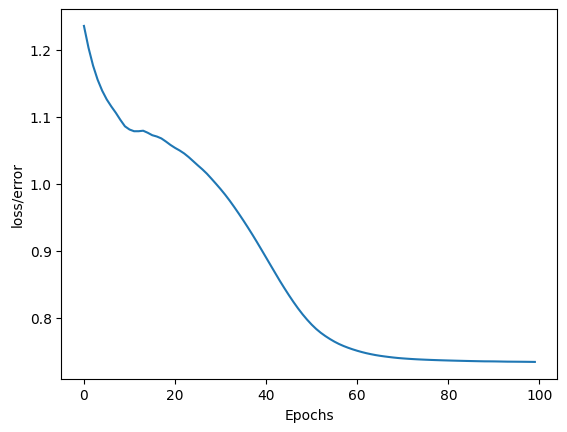

In [62]:
# graph it out
import matplotlib.pyplot as plt
plt.plot(range(epochs),losses)
plt.ylabel("loss/error")
plt.xlabel("Epochs")
plt.show()